# MODEL_CF — UserCF canonique

Ce notebook documente le modèle UserCF servi par NextWatch. Le protocole déterministe sépare les interactions en **65 % entraînement, 15 % validation et 20 % test** (`random_state=42`). Les hyperparamètres sont choisis uniquement sur la validation ; l’artefact est ensuite construit sur entraînement + validation, tandis que le test reste réservé à l’évaluation finale.

Les cas produit utilisent 1 à 3 films aimés, avec la définition canonique `rating > user_mean(reference)`.


## 1. Sources canoniques et imports


In [15]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 42
FIXED_TRAIN_FRAC = 0.65
np.random.seed(RANDOM_STATE)

GENRES = [
    "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime",
    "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical",
    "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western",
]

DATA_DIR = next(
    (p for p in [Path("dataset"), Path("../dataset")] if (p / "u.data.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("dataset/ introuvable")

notes = pd.read_csv(DATA_DIR / "u.data.csv")
films = pd.read_csv(DATA_DIR / "u.item.csv")
users = pd.read_csv(DATA_DIR / "u.user.csv", dtype={"zip_code": "string"}).drop(
    columns=["occupation"], errors="ignore"
)
df = notes.merge(users, on="user_id", how="left").merge(
    films, left_on="item_id", right_on="movie_id", how="left"
)
df = df.loc[df["unknown"] != 1].drop(columns=["unknown"]).copy()
df["genres"] = df[GENRES].apply(lambda row: [g for g in GENRES if row[g] == 1], axis=1)
print(f"Notes : {len(df):,} | users : {df['user_id'].nunique()} | films : {df['item_id'].nunique()}")

# --- Chargement des hyperparamètres optimisés Optuna ---
opt_path = Path("results/best_hyperparams_cf_optuna.json")
if opt_path.exists():
    print(f"Chargement des hyperparamètres depuis {opt_path}")
    best_params = json.loads(opt_path.read_text(encoding="utf-8"))
else:
    print("Fichier d'optimisation non trouvé. Utilisation des valeurs par défaut.")
    best_params = {}

MIN_SUPPORT = int(best_params.get("MIN_SUPPORT", 34))
CF_N_USER = int(best_params.get("CF_N_USER", 180))
CF_N_FILM = int(best_params.get("CF_N_FILM", 50))
HYBRID_ALPHA = float(best_params.get("HYBRID_ALPHA", 0.75))
HYBRID_POOL = int(best_params.get("HYBRID_POOL", 270))
DEMO_SEX_WEIGHT = float(best_params.get("DEMO_SEX_WEIGHT", 0.05))
AGE_SCALE = float(best_params.get("AGE_SCALE", 30))
GENRE_BOOST = float(best_params.get("GENRE_BOOST", 1.05))
MAX_SEEDS = int(best_params.get("MAX_SEEDS", 7))
RRF_K = float(best_params.get("RRF_K", 24.0))
SUBLINEAR_TF = bool(best_params.get("SUBLINEAR_TF", False))
RATING_POWER = float(best_params.get("RATING_POWER", 0.75))
MIN_GENRE_MATCH = int(best_params.get("MIN_GENRE_MATCH", 3))

display(df[["user_id", "item_id", "rating", "age", "gender", "title", "genres"]].head(3))


Notes : 99,990 | users : 943 | films : 1680
Fichier d'optimisation non trouvé. Utilisation des valeurs par défaut.


,user_id,item_id,rating,age,gender,title,genres
0,196,242,3,49,M,Kolya (1996),[Comedy]
1,186,302,3,39,F,L.A. Confidential (1997),"[Crime, Film-Noir, Mystery, Thriller]"
2,22,377,1,25,M,Heavyweights (1994),"[Children's, Comedy]"


In [16]:
train = df.sample(frac=FIXED_TRAIN_FRAC, random_state=RANDOM_STATE)
test = df.drop(train.index)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)
print(f"Train {len(train):,} | Test {len(test):,}")

movies = df.drop_duplicates("item_id").set_index("item_id")
movie_genres = movies["genres"].to_dict()
movie_title = movies["title"].to_dict()
film_genre_X = movies[GENRES].astype(float)
all_movie_ids = film_genre_X.index.to_numpy()
print(f"Films catalogue : {len(all_movie_ids)}")


Train 64,994 | Test 34,996
Films catalogue : 1680


## 2. Stats + cas d'évaluation


In [17]:
film_stats = (
    train.groupby("item_id")["rating"]
    .agg(n_ratings="count", mean_rating="mean")
    .reset_index()
)
eligible = film_stats.loc[film_stats["n_ratings"] >= MIN_SUPPORT].set_index("item_id")
mean_rating = eligible["mean_rating"]
print(f"Films éligibles (>= {MIN_SUPPORT} notes) : {len(eligible)}")

user_mean = train.groupby("user_id")["rating"].mean()
train = train.copy()
test = test.copy()
train["user_mean"] = train["user_id"].map(user_mean)
test["user_mean"] = test["user_id"].map(user_mean)
liked_train = train.loc[train["rating"] > train["user_mean"]]
liked_test = test.loc[test["rating"] > test["user_mean"]]
print(
    f"Aimé (note > moyenne user) : train {len(liked_train):,} | test {len(liked_test):,} "
    f"| moyenne des moyennes user = {user_mean.mean():.2f}"
)
train_counts = train.groupby("item_id").size()
cand_A = liked_train.copy()
cand_A["pop"] = cand_A["item_id"].map(train_counts)

def _get_top_seeds(df_u, max_n=MAX_SEEDS):
    sorted_u = df_u.sort_values(["rating", "pop"], ascending=[False, False])
    return list(sorted_u["item_id"].unique()[:max_n])

seeds_per_user = (
    cand_A.groupby("user_id", group_keys=False).apply(_get_top_seeds).rename("query_ids")
)
user_demo = train.drop_duplicates("user_id").set_index("user_id")[["age", "gender"]]
relevant = liked_test.groupby("user_id")["item_id"].apply(set).rename("relevant_ids")
liked_lists = liked_train.groupby("user_id")["item_id"].apply(set)

eval_cases = pd.concat([seeds_per_user, user_demo, relevant], axis=1, join="inner").reset_index()
eval_cases["relevant_ids"] = eval_cases.apply(
    lambda r: r["relevant_ids"] - set(r["query_ids"]), axis=1
)
eval_cases = eval_cases.loc[eval_cases["relevant_ids"].map(len) > 0].reset_index(drop=True)
eval_cases["liked_train_ids"] = eval_cases["user_id"].map(liked_lists)
print(f"Cas d'évaluation (1-{MAX_SEEDS} films) : {len(eval_cases)}")
display(eval_cases.head(3))


Films éligibles (>= 34 notes) : 597
Aimé (note > moyenne user) : train 34,991 | test 19,069 | moyenne des moyennes user = 3.58
Cas d'évaluation (1-7 films) : 937


,user_id,query_ids,age,gender,relevant_ids,liked_train_ids
0,1,"[50, 181, 258, 174, 168, 64, 183]",24,M,"{256, 1, 257, 269, 14, 270, 16, 15, 18, 19, 23...","{3, 6, 7, 9, 12, 13, 20, 22, 25, 28, 32, 33, 4..."
1,2,"[50, 127, 302, 275, 272, 285, 316]",53,F,"{1, 100, 293, 299, 13, 237, 251, 273, 306, 277...","{257, 255, 269, 14, 272, 275, 276, 279, 25, 28..."
2,3,"[340, 321, 320, 181, 260, 331, 342]",23,M,"{327, 328, 299, 303, 344, 345, 346, 347, 348, ...","{260, 268, 271, 307, 181, 320, 321, 322, 329, ..."


## 3. Matrices CF (train uniquement)


In [18]:
users_u = sorted(train["user_id"].unique())
items_u = sorted(train[train["item_id"].isin(eligible.index)]["item_id"].unique())
u_ix = {u: i for i, u in enumerate(users_u)}
i_ix = {it: i for i, it in enumerate(items_u)}

train_filtered = train[train["item_id"].isin(eligible.index)]
mat_ui = csr_matrix(
    (
        train_filtered["rating"].astype(float).values,
        (train_filtered["user_id"].map(u_ix).values, train_filtered["item_id"].map(i_ix).values),
    ),
    shape=(len(users_u), len(items_u)),
)
mat_iu_tfidf = TfidfTransformer(sublinear_tf=SUBLINEAR_TF).fit_transform(mat_ui.T.tocsr())
nn_item = NearestNeighbors(metric="cosine", algorithm="brute")
nn_item.fit(mat_iu_tfidf)
n_ask_i = min(CF_N_FILM + 1, len(items_u))
d_i, ix_i = nn_item.kneighbors(mat_iu_tfidf, n_neighbors=n_ask_i)
item_ids_arr = np.array(items_u)

CF_ITEM = {}
for i, mid in enumerate(items_u):
    CF_ITEM[mid] = [
        (int(item_ids_arr[j]), 1.0 - float(d))
        for d, j in zip(d_i[i], ix_i[i])
        if int(item_ids_arr[j]) != mid
    ]

liked_by_user = (
    liked_train.groupby("user_id")[["item_id", "rating"]]
    .apply(lambda x: list(zip(x["item_id"], x["rating"])))
    .to_dict()
)
fans_of = {
    mid: list(
        zip(
            grp["user_id"].to_numpy(),
            grp["rating"].to_numpy(),
            grp["age"].to_numpy(),
            grp["gender"].to_numpy(),
        )
    )
    for mid, grp in liked_train.groupby("item_id")
}
print(f"Film–Film CF : {len(CF_ITEM)} films | User–CF fans_of={len(fans_of)}")
print(f"Hybride alpha={HYBRID_ALPHA} | RRF_K={RRF_K} | GenreBoost={GENRE_BOOST}")


Film–Film CF : 597 films | User–CF fans_of=1412
Hybride alpha=0.75 | RRF_K=24.0 | GenreBoost=1.05


## 4. Recommenders


In [19]:
def _seen(query_ids, liked_train_ids):
    if isinstance(query_ids, (int, np.integer)):
        seeds = {int(query_ids)}
    else:
        seeds = set(int(x) for x in query_ids)
    s = set(liked_train_ids) if liked_train_ids is not None else set()
    return s.union(seeds), seeds

def recommend_baseline(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    union_g = set()
    for qid in seeds:
        union_g.update(movie_genres.get(qid, []))
    if not union_g:
        return []
    scores = [
        (mid, float(m))
        for mid, m in mean_rating.items()
        if mid not in seen and union_g & set(movie_genres.get(mid, []))
    ]
    scores.sort(key=lambda x: (-x[1], x[0]))
    return [m for m, _ in scores[:k]]

def _demo_sim(age_a, gender_a, age_b, gender_b):
    sex = 1.0 if gender_a == gender_b else 0.0
    age_term = 1.0 - min(abs(float(age_a) - float(age_b)) / AGE_SCALE, 1.0)
    return DEMO_SEX_WEIGHT * sex + (1.0 - DEMO_SEX_WEIGHT) * age_term

def recommend_user_cf(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    age_val = 30.0 if age is None else float(age)
    gender_val = "M" if gender is None else gender
    neighbors = []
    for qid in seeds:
        for uid, rat, a, g in fans_of.get(qid, []):
            sim = _demo_sim(age_val, gender_val, a, g)
            weighted_rat = (float(rat) ** RATING_POWER) / (5.0 ** RATING_POWER)
            neighbors.append((int(uid), sim * weighted_rat))
    neighbors.sort(key=lambda x: -x[1])
    neighbors = neighbors[:CF_N_USER]
    scores = {}
    for vid, sim in neighbors:
        for mid, rat in liked_by_user.get(vid, []):
            if mid in seen:
                continue
            scores[mid] = scores.get(mid, 0.0) + float(sim) * (float(rat) ** RATING_POWER)
    return [m for m, _ in sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:k]]

def recommend_film_cf(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    scores = {}
    for qid in seeds:
        for mid, sim in CF_ITEM.get(qid, []):
            if mid in seen:
                continue
            scores[mid] = scores.get(mid, 0.0) + sim
    return [m for m, _ in sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:k]]

def recommend_hybrid(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None,
                     alpha=None, pool=HYBRID_POOL):
    alpha_val = HYBRID_ALPHA if alpha is None else float(alpha)
    pool_val = max(pool, k)
    film_list = recommend_film_cf(query_ids, k=pool_val, age=age, gender=gender, liked_train_ids=liked_train_ids, user_id=user_id)
    user_list = recommend_user_cf(query_ids, k=pool_val, age=age, gender=gender, liked_train_ids=liked_train_ids, user_id=user_id)
    
    scores = {}
    for rank, mid in enumerate(film_list):
        scores[mid] = scores.get(mid, 0.0) + alpha_val / (RRF_K + rank)
    for rank, mid in enumerate(user_list):
        scores[mid] = scores.get(mid, 0.0) + (1.0 - alpha_val) / (RRF_K + rank)
        
    _, seeds = _seen(query_ids, liked_train_ids)
    union_g = set()
    for qid in seeds:
        union_g.update(movie_genres.get(qid, []))
    for mid in list(scores.keys()):
        common_genres = len(union_g & set(movie_genres.get(mid, [])))
        if common_genres >= MIN_GENRE_MATCH:
            scores[mid] *= GENRE_BOOST
            
    return [m for m, _ in sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:k]]

ex = eval_cases.iloc[0]
qids = ex["query_ids"]
kw = dict(age=ex["age"], gender=ex["gender"], liked_train_ids=ex["liked_train_ids"], user_id=ex["user_id"])
print("Seeds :", [movie_title.get(i) for i in qids])
print("Baseline:", [movie_title.get(i) for i in recommend_baseline(qids, 5, **kw)])
print("UserCF  :", [movie_title.get(i) for i in recommend_user_cf(qids, 5, **kw)])
print("FilmCF  :", [movie_title.get(i) for i in recommend_film_cf(qids, 5, **kw)])
print("Hybrid  :", [movie_title.get(i) for i in recommend_hybrid(qids, 5, **kw)])


Seeds : ['Star Wars (1977)', 'Return of the Jedi (1983)', 'Contact (1997)', 'Raiders of the Lost Ark (1981)', 'Monty Python and the Holy Grail (1974)', 'Shawshank Redemption, The (1994)', 'Alien (1979)']
Baseline: ['Casablanca (1942)', "Schindler's List (1993)", 'Close Shave, A (1995)', 'Third Man, The (1949)', 'Rear Window (1954)']
UserCF  : ['Princess Bride, The (1987)', 'Empire Strikes Back, The (1980)', 'Aliens (1986)', 'Pulp Fiction (1994)', 'Back to the Future (1985)']
FilmCF  : ['Empire Strikes Back, The (1980)', 'Back to the Future (1985)', 'Aliens (1986)', 'Pulp Fiction (1994)', 'Terminator 2: Judgment Day (1991)']
Hybrid  : ['Empire Strikes Back, The (1980)', 'Aliens (1986)', 'Back to the Future (1985)', 'Princess Bride, The (1987)', 'Pulp Fiction (1994)']


## 5. Évaluation produit

Variance P@5 et popularité : `CONCLUSION.ipynb` §3 (export `results/eval_cf.json`).


Situation produit — 937 cas


,method,P@5,P@10
0,baseline_overlap_mean,0.0794,0.0796
1,model_user_user_cf,0.1816,0.1564
2,model_film_film_cf,0.2284,0.1942
3,model_hybrid_film_user,0.2292,0.1951



Lift vs baseline (P@5) :
  model_user_user_cf       lift=+0.1022  p=2.61e-48
  model_film_film_cf       lift=+0.1490  p=5.20e-75
  model_hybrid_film_user   lift=+0.1498  p=1.03e-78


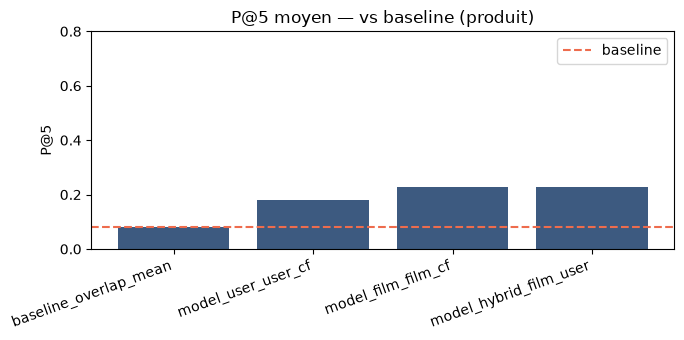

Export diagnostics → C:\Users\tombo\Documents\cours\data\lab\NextWatch\results\eval_cf.json


In [20]:
import sys
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt

_ROOT = next(p for p in [Path("."), Path("..")] if (p / "scripts" / "Models" / "eval_diagnostics.py").exists())
sys.path.insert(0, str((_ROOT / "scripts" / "Models").resolve()))
from eval_diagnostics import collect_method_eval, save_eval_bundle

methods = [
    ("baseline_overlap_mean", recommend_baseline),
    ("model_user_user_cf", recommend_user_cf),
    ("model_film_film_cf", recommend_film_cf),
    ("model_hybrid_film_user", recommend_hybrid),
]

method_data = {name: collect_method_eval(fn, eval_cases) for name, fn in methods}
results_product = pd.DataFrame([
    {
        "method": name,
        "P@5": float(np.mean(d["P@5"])),
        "P@10": float(np.mean(d["P@10"])),
    }
    for name, d in method_data.items()
])
print(f"Situation produit — {len(eval_cases)} cas")
display(results_product.round(4))

base = np.asarray(method_data["baseline_overlap_mean"]["P@5"])
print("\nLift vs baseline (P@5) :")
for name, d in method_data.items():
    if name == "baseline_overlap_mean":
        continue
    s = np.asarray(d["P@5"])
    lift = s.mean() - base.mean()
    p = stats.ttest_rel(s, base).pvalue
    print(f"  {name:24s} lift={lift:+.4f}  p={p:.2e}")

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(results_product))
ax.bar(x, results_product["P@5"], color="#3d5a80")
ax.axhline(base.mean(), color="#ee6c4d", ls="--", label="baseline")
ax.set_xticks(x)
ax.set_xticklabels(results_product["method"], rotation=20, ha="right")
ax.set_ylabel("P@5")
ax.set_ylim(0, 0.8)
ax.set_title("P@5 moyen — vs baseline (produit)")
ax.legend()
plt.tight_layout()
plt.show()

out = save_eval_bundle(
    "cf",
    method_data,
    film_stats.set_index("item_id")["n_ratings"],
    n_cases=len(eval_cases),
    random_state=RANDOM_STATE,
    train_frac=FIXED_TRAIN_FRAC,
)
print(f"Export diagnostics → {out}")


## 6. Suite

Variance et popularité (tous modèles) : **`CONCLUSION.ipynb`** §3.


In [21]:
print("Ouvrir CONCLUSION.ipynb (section 3) après export eval_cf.json")


Ouvrir CONCLUSION.ipynb (section 3) après export eval_cf.json
